# Ring analysis around charcoal kilns: example

This notebook shows how to use the two scripts:

- `kiln_ring_analysis.py`: samples a raster along radial transects around every kiln and computes a mean and median per distance ring.
- `plot_kiln_rings.py`: draws the three-panel figure from the results.

Both are used the same way: you pass a dict with the parameters you want to change, and everything you leave out falls back to the `DEFAULTS` at the top of each file.

In [ ]:
# --- Project paths ------------------------------------------------------------
# Modules are in src/, data in data/, results in results/, figures in figures/.
# Works no matter from which folder the notebook is started.
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "paths.py").exists())
sys.path.insert(0, str(ROOT / "src"))

from paths import data, DATA_RAW, DATA_PROCESSED, RESULTS, FIGURES
import helpers
helpers.FIG_DIR = FIGURES / "00_example"     # save_fig() writes here
helpers.FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Setup

Save this notebook in the same folder as the two `.py` files. If it lives somewhere else, uncomment the `sys.path` line and put in the folder that contains the scripts.

`autoreload` makes the notebook pick up changes to the `.py` files without restarting the kernel.

In [2]:
%load_ext autoreload
%autoreload 2

from kiln_ring_analysis import kiln_ring_analysis, DEFAULTS as ANALYSIS_DEFAULTS
from plot_kiln_rings import plot_kiln_rings, DEFAULTS as PLOT_DEFAULTS
from helpers import save_fig

## 2. Available parameters

These are all the keys you can put in the parameter dict, with their default values. Any other key raises an error, so typos are caught.

In [3]:
ANALYSIS_DEFAULTS

{'gpkg': 'kohlmeiler_2056.gpkg',
 'id_column': 'ID_PAROLINI',
 'tif': 'merged_dem.tif',
 'band': 1,
 'rings': [(0, 6), (6, 12), (12, 18), (18, 24)],
 'n_rays': 16,
 'step': 1,
 'weighted': False,
 'include_centre': False,
 'min_valid': 0.9,
 'summary_of': 'mean',
 'out_dir': 'results',
 'out_prefix': None,
 'comment': None,
 'save': True,
 'verbose': True}

In [4]:
PLOT_DEFAULTS

{'rings_csv': 'merged_dem_rings.csv',
 'value': 'mean',
 'y_label': 'Canopy height (m)',
 'color': '#23794A',
 'out_png': None,
 'save': True,
 'dpi': 200,
 'figsize': (16, 5.2),
 'show': True,
 'seed': 0}

| Key | Meaning |
|---|---|
| `gpkg` | GeoPackage with the kiln points |
| `id_column` | Column that identifies each kiln |
| `tif` | Raster to analyse |
| `band` | Band number of the raster |
| `rings` | List of `(inner, outer)` distances in metres, from inside to outside |
| `n_rays` | Number of directions, evenly spread over 360° |
| `step` | Spacing of samples along each ray, in metres |
| `weighted` | `True`: weight samples by distance (area mean); `False`: all samples count equally |
| `include_centre` | Whether the value at the kiln itself is part of the first ring |
| `min_valid` | A ring is left empty if less than this share of its samples has data |
| `summary_of` | Per-kiln value used in the overview: `"mean"` or `"median"` |
| `out_dir` | Folder for the output files |
| `out_prefix` | File name prefix (`None` = raster name) |
| `save` | Write the output files |
| `verbose` | Print the overview |

File paths are relative to the folder this notebook is in.

## 3. Run the analysis

Only list what you want to change from the defaults.

In [5]:
rings = [(0, 6), (6, 12), (12, 18), (18, 24), (24, 30), (30, 36)]
params = {
    "gpkg": data("kohlmeiler_2056_reduced.gpkg"),
    "tif": data("merged_dem.tif"),
    "rings": rings,
    "n_rays": 8,
    "step": 1,
    "weighted": False
}

out = kiln_ring_analysis(params)

Raster:        merged_dem.tif
Band:          1 of 1 (no name)
CRS:           EPSG:2056
Pixel size:    1.0 x 1.0 m
Nodata value:  -999999.0
Kilns:         60 from kohlmeiler_2056_reduced.gpkg
Rays:          8 (every 45°), sample every 1 m up to 36 m
Weighted:      False
Centre used:   False
Samples per ring (identical for every kiln):
       0-6     m: 48 samples
       6-12    m: 48 samples
      12-18    m: 48 samples
      18-24    m: 48 samples
      24-30    m: 48 samples
      30-36    m: 48 samples

Overview across all kilns (each kiln = one ring mean, unweighted):
        0-6 m  6-12 m  12-18 m  18-24 m  24-30 m  30-36 m
count   60.00   60.00    60.00    60.00    60.00    60.00
median   6.74    5.97     6.21     6.58     6.19     6.44
mean     7.69    7.25     7.22     7.52     7.29     7.63
std      3.49    3.10     3.33     3.21     3.05     3.32
min      3.22    2.44     2.35     3.14     2.90     3.63
25%      5.31    5.28     5.17     5.37     5.39     5.34
50%      6.74   

## 4. Look at the results

`out` is a dict:

- `out["summary"]`: overview across all kilns, one column per ring
- `out["rings"]`: one row per kiln with mean, median, number of samples and valid share per ring
- `out["samples"]`: every single sample (kiln, ray, distance, ring, value, ...)
- `out["files"]`: paths of the written files
- `out["params"]`: the full parameter set that was used

In [6]:
out["summary"].round(2)

,0-6 m,6-12 m,12-18 m,18-24 m,24-30 m,30-36 m
count,60.00,60.00,60.00,60.00,60.00,60.00
median,6.74,5.97,6.21,6.58,6.19,6.44
mean,7.69,7.25,7.22,7.52,7.29,7.63
std,3.49,3.10,3.33,3.21,3.05,3.32
min,3.22,2.44,2.35,3.14,2.90,3.63
25%,5.31,5.28,5.17,5.37,5.39,5.34
50%,6.74,5.97,6.21,6.58,6.19,6.44
75%,8.89,8.72,8.58,8.87,7.98,8.74
max,19.29,16.50,19.60,17.61,15.12,17.20


In [7]:
out["rings"].head()

,x,y,mean_0_6,median_0_6,n_0_6,valid_0_6,mean_6_12,median_6_12,n_6_12,valid_6_12,...,n_18_24,valid_18_24,mean_24_30,median_24_30,n_24_30,valid_24_30,mean_30_36,median_30_36,n_30_36,valid_30_36
kiln_id,,,,,,,,,,,,,,,,,,,,,
1,2.808165e+06,1.171932e+06,8.390000,7.140000,48,1.0,9.818333,7.70,48,1.0,...,48,1.0,14.545833,14.67,48,1.0,15.257500,17.000000,48,1.0
6,2.809141e+06,1.169552e+06,5.385833,2.660000,48,1.0,10.531875,10.53,48,1.0,...,48,1.0,12.216875,12.31,48,1.0,12.141667,12.070000,48,1.0
8,2.809520e+06,1.168555e+06,15.855833,18.700001,48,1.0,13.283958,14.89,48,1.0,...,48,1.0,13.115000,14.90,48,1.0,17.197292,18.969999,48,1.0
9,2.809624e+06,1.168257e+06,6.266042,5.490000,48,1.0,5.354583,4.00,48,1.0,...,48,1.0,5.168125,3.36,48,1.0,6.873958,7.080000,48,1.0
10,2.809695e+06,1.168169e+06,8.832917,9.630000,48,1.0,7.790625,8.63,48,1.0,...,48,1.0,5.964792,7.71,48,1.0,9.076250,9.680000,48,1.0


In [8]:
out["samples"].head()

,kiln_id,kiln_x,kiln_y,ray,bearing,distance,ring,ring_index,x,y,value,valid,weight
0,1,2.808165e+06,1.171932e+06,0,0.0,1.0,0-6,0,2.808165e+06,1.171933e+06,9.82,True,1.0
1,1,2.808165e+06,1.171932e+06,0,0.0,2.0,0-6,0,2.808165e+06,1.171934e+06,7.00,True,1.0
2,1,2.808165e+06,1.171932e+06,0,0.0,3.0,0-6,0,2.808165e+06,1.171935e+06,2.14,True,1.0
3,1,2.808165e+06,1.171932e+06,0,0.0,4.0,0-6,0,2.808165e+06,1.171936e+06,2.18,True,1.0
4,1,2.808165e+06,1.171932e+06,0,0.0,5.0,0-6,0,2.808165e+06,1.171937e+06,4.71,True,1.0


In [9]:
out["files"]

{'rings': PosixPath('results/merged_dem_rays8_step1_ring6x6_reduced/merged_dem_reduced_rings.csv'),
 'summary': PosixPath('results/merged_dem_rays8_step1_ring6x6_reduced/merged_dem_reduced_summary.csv'),
 'samples_csv': PosixPath('results/merged_dem_rays8_step1_ring6x6_reduced/merged_dem_reduced_samples.csv'),
 'samples_gpkg': PosixPath('results/merged_dem_rays8_step1_ring6x6_reduced/merged_dem_reduced_samples.gpkg')}

## 5. Plot

Pass the path of the `_rings.csv` file that the analysis wrote. Assign the result to a variable (`fig = ...`) so the figure is not shown twice.

60 RCM, rings: 0-6 m, 6-12 m, 12-18 m, 18-24 m, 24-30 m, 30-36 m
RCMs with at least one empty ring: 0
Saved results/merged_dem_rays8_step1_ring6x6_reduced/merged_dem_reduced_rings_mean_plot.png


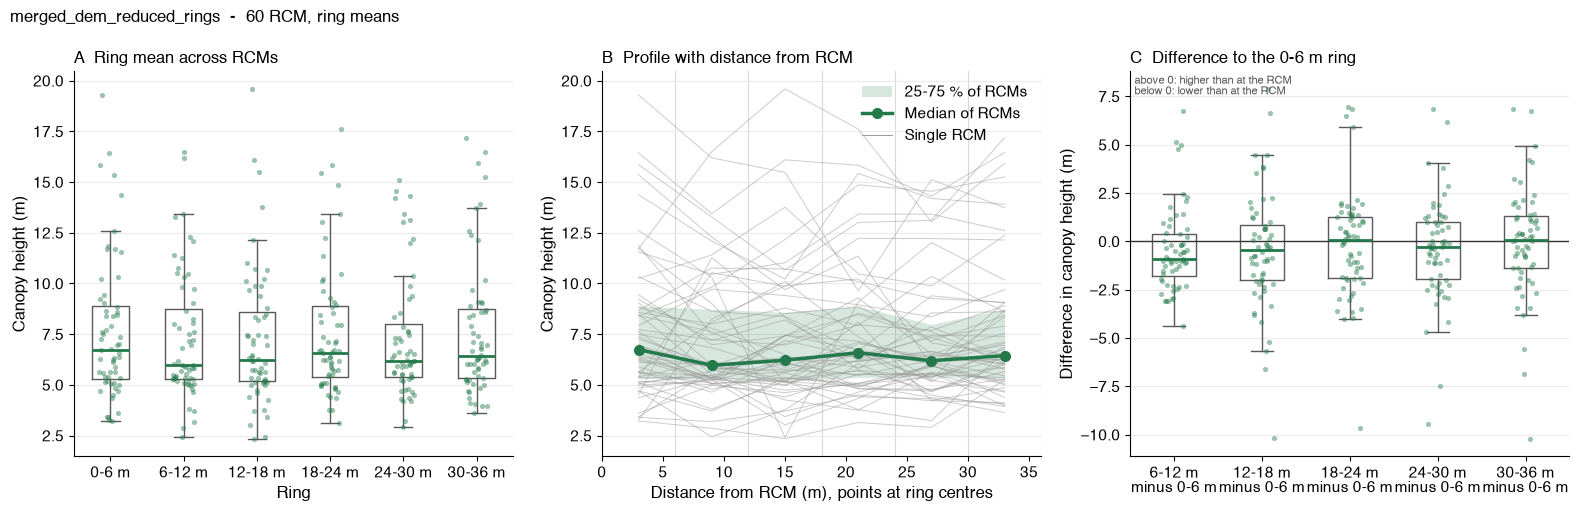

1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp
1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


[PosixPath('/Users/paulghisletti/Desktop/GEO715/GEO-715-Project/new testfolder/figures/rays8_step1_ring6x6_reduced_boxplots.png'),
 PosixPath('/Users/paulghisletti/Desktop/GEO715/GEO-715-Project/new testfolder/figures/rays8_step1_ring6x6_reduced_boxplots.pdf')]

In [10]:
fig = plot_kiln_rings({
    "rings_csv": out["files"]["rings"],
    "value": "mean",
    "y_label": "Canopy height (m)",
})

save_fig("rays8_step1_ring6x6_reduced_boxplots", fig=fig)

## 6. Several rasters in a loop

`{**params, "tif": tif}` copies the parameters from above and swaps only the raster. Outputs are named after each raster, so nothing is overwritten. Replace the file names and y-axis labels with your own.

60 RCM, rings: 0-6 m, 6-12 m, 12-18 m, 18-24 m, 24-30 m, 30-36 m
RCMs with at least one empty ring: 0
Saved results/merged_dem_rays8_step1_ring6x6_reduced/merged_dem_reduced_rings_mean_plot.png


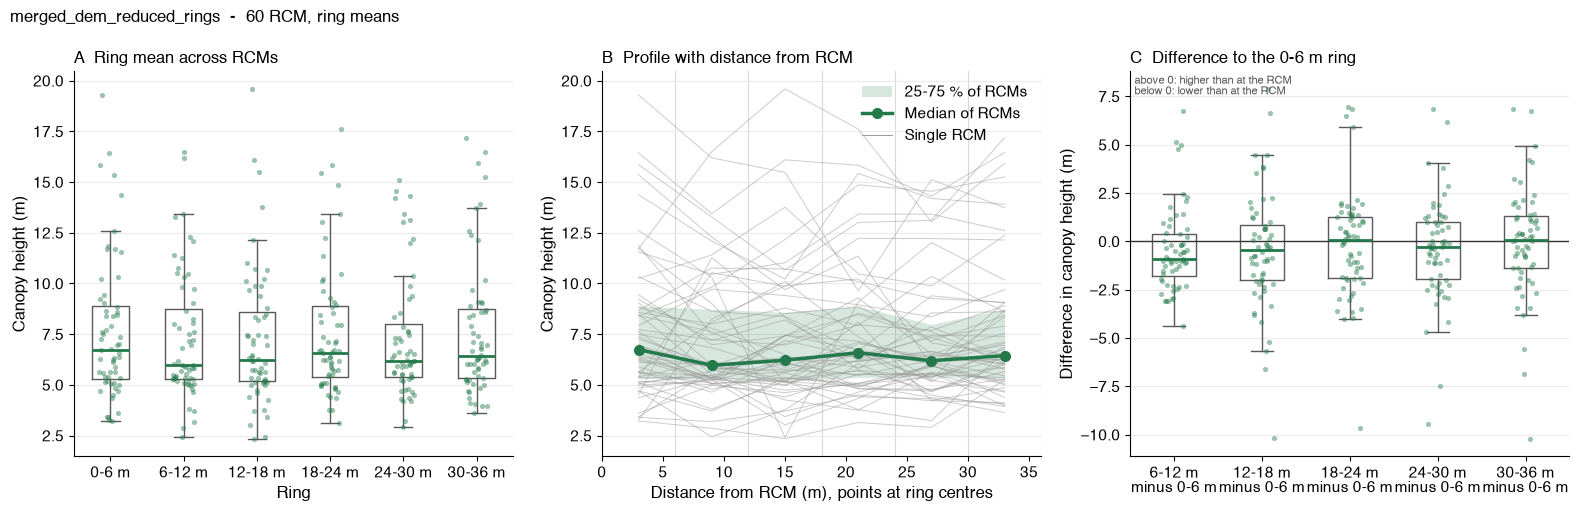

In [11]:
rasters = {
    data("merged_dem.tif"): "Canopy height (m)",
    # data("canopy_height.tif"): "Canopy height (m)",
}

results = {}
for tif, y_label in rasters.items():
    results[tif] = kiln_ring_analysis({**params, "tif": tif, "verbose": False})
    fig = plot_kiln_rings({"rings_csv": results[tif]["files"]["rings"], "y_label": y_label})

## 7. Comparing settings

The same idea works for testing a setting, for example weighted against unweighted. Here nothing is saved; only the summaries are compared.

In [12]:
import pandas as pd

compare = {}
for w in (False, True):
    res = kiln_ring_analysis({**params, "weighted": w, "save": False, "verbose": False})
    compare["weighted" if w else "unweighted"] = res["summary"].loc["median"]

pd.DataFrame(compare).round(2)

,unweighted,weighted
0-6 m,6.74,6.56
6-12 m,5.97,5.96
12-18 m,6.21,6.22
18-24 m,6.58,6.58
24-30 m,6.19,6.21
30-36 m,6.44,6.51
